# 06 · Polls against results

Part 2 of the study plan (`docs/study_plan.md`): how much coordination the polls show, toward whom, and how they
compare with the result. Built block by block: **structure metrics**, then the split of the change in concentration,
poll error by role, the cliff, the last weeks, momentum, and a table of stylized facts.

Each poll is read through its ballot scenario, with every candidate it tests, including those who will not be on the
ballot: that is what voters saw. Shares are rescaled to 100 unless marked *raw*.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from polls import average, metrics, timeline

pd.set_option("display.width", 200)
TABLES, FIGURES = ROOT / "results" / "tables", ROOT / "results" / "figures"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

calendar = timeline.load(ROOT / "config" / "elections.yaml")
rows = timeline.add_time(pd.read_csv(ROOT / "data" / "final" / "polls.csv", low_memory=False), calendar)
results = pd.read_csv(ROOT / "data" / "interim" / "results.csv")
ELECTIONS = sorted(rows["election"].unique())
ballot = rows[rows["ballot_scenario"] & (rows["share_status"] != "not_tested")]
# one colour per election, from the same left-right palette's ends inward (no ideological meaning here)
E_COLOURS = dict(zip(ELECTIONS, ["#9e0142", "#f46d43", "#e09000", "#2a9d8f", "#5e4fa2"]))

## 1 · Structure metrics

For each poll's ballot scenario and each result: HHI (rescaled and raw) and ENP = 1 / HHI; the top-two share; the
**cliff** (2nd − 3rd, in points, and relative to the 2nd's share); the 1st–2nd and 3rd–4th gaps; the number of
candidates within 5 points of the 2nd (the 2nd included).

In [2]:
per_poll = []
for (e, pid), g in ballot.groupby(["election", "poll_id"]):
    st = metrics.structure(metrics.shares_of(g))
    per_poll.append(dict(election=e, poll_id=pid, days_before=g["days_before"].iloc[0], phase=g["phase"].iloc[0],
                         n_extra=int(g["slot"].isna().sum()), **st))
per_poll = pd.DataFrame(per_poll)
per_poll.round(4).to_csv(TABLES / "structure_by_poll.csv", index=False)

res_rows = results.assign(share_status="value", share_upper_bound=np.nan)
per_result = pd.DataFrame([dict(election=e, **metrics.structure(metrics.shares_of(g)))
                           for e, g in res_rows.groupby("election")]).set_index("election")
per_result.round(4).to_csv(TABLES / "structure_results.csv")
cols = ["n_candidates", "hhi", "enp", "top2_share", "gap_12", "cliff", "cliff_rel", "gap_34", "n_in_contention",
        "first", "second", "third"]
print("Results:")
per_result[cols].round(3)

Results:


,n_candidates,hhi,enp,top2_share,gap_12,cliff,cliff_rel,gap_34,n_in_contention,first,second,third
election,,,,,,,,,,,,
2002,16,0.115,8.659,36.74,3.02,0.68,0.040,9.34,2,Jacques Chirac,Jean-Marie Le Pen,Lionel Jospin
2007,12,0.213,4.700,57.05,5.31,7.30,0.282,8.13,1,Nicolas Sarkozy,Ségolène Royal,François Bayrou
2012,10,0.210,4.772,55.81,1.45,9.28,0.341,6.80,1,François Hollande,Nicolas Sarkozy,Marine Le Pen
2017,11,0.188,5.318,45.31,2.71,1.29,0.061,0.43,3,Emmanuel Macron,Marine Le Pen,François Fillon
2022,12,0.191,5.231,51.00,4.70,1.20,0.052,14.88,2,Emmanuel Macron,Marine Le Pen,Jean-Luc Mélenchon


### The last polls against the result

Mean over the polls of the last two weeks, against the result. *Raw HHI* uses shares as published (they can sum below
100 when small candidates are missing), so it is lower than the rescaled HHI in 2007 and 2012.

In [3]:
last = per_poll[per_poll["phase"] == timeline.PHASES[2]]
num = ["hhi", "hhi_raw", "enp", "top2_share", "gap_12", "cliff", "cliff_rel", "gap_34", "n_in_contention", "total"]
cmp = pd.concat({"last polls": last.groupby("election")[num].mean(),
                 "result": per_result[num]}, axis=1).swaplevel(axis=1).sort_index(axis=1, level=0)
for m in num:
    cmp[(m, "difference")] = cmp[(m, "result")] - cmp[(m, "last polls")]
cmp = cmp.reindex(columns=pd.MultiIndex.from_product([num, ["last polls", "result", "difference"]]))
cmp.round(3).to_csv(TABLES / "structure_last_polls_vs_result.csv")
cmp[["hhi", "enp", "top2_share", "cliff", "gap_12"]].round(3)

hhi                          enp                   top2_share                        cliff                       gap_12                  
         last polls result difference last polls result difference last polls result difference last polls result difference last polls result difference
election                                                                                                                                                 
2002          0.115  0.115      0.001      8.732  8.659     -0.073     38.000  36.74     -1.260      5.250   0.68     -4.570      2.083   3.02      0.937
2007          0.196  0.213      0.017      5.099  4.700     -0.399     52.444  57.05      4.606      5.528   7.30      1.772      4.333   5.31      0.977
2012          0.207  0.210      0.003      4.834  4.772     -0.062     55.042  55.81      0.768     10.833   9.28     -1.553      1.625   1.45     -0.175
2017          0.187  0.188      0.001      5.340  5.318     -0.022     46.182  45.31     -0.872      2.955   1.29     -1.665      1.182   2.71      1.528
2022          0.170  0.191      0.021      5.889  5.231     -0.657     48.867  51.00      2.133      5.945   1.20     -4.745      4.788   4.70     -0.088

### Over the campaign

Poll average of each metric (same kernel as in notebook 05: 10 days, at least 3 polls nearby) over the last 365 days;
dots at 0 are the results.

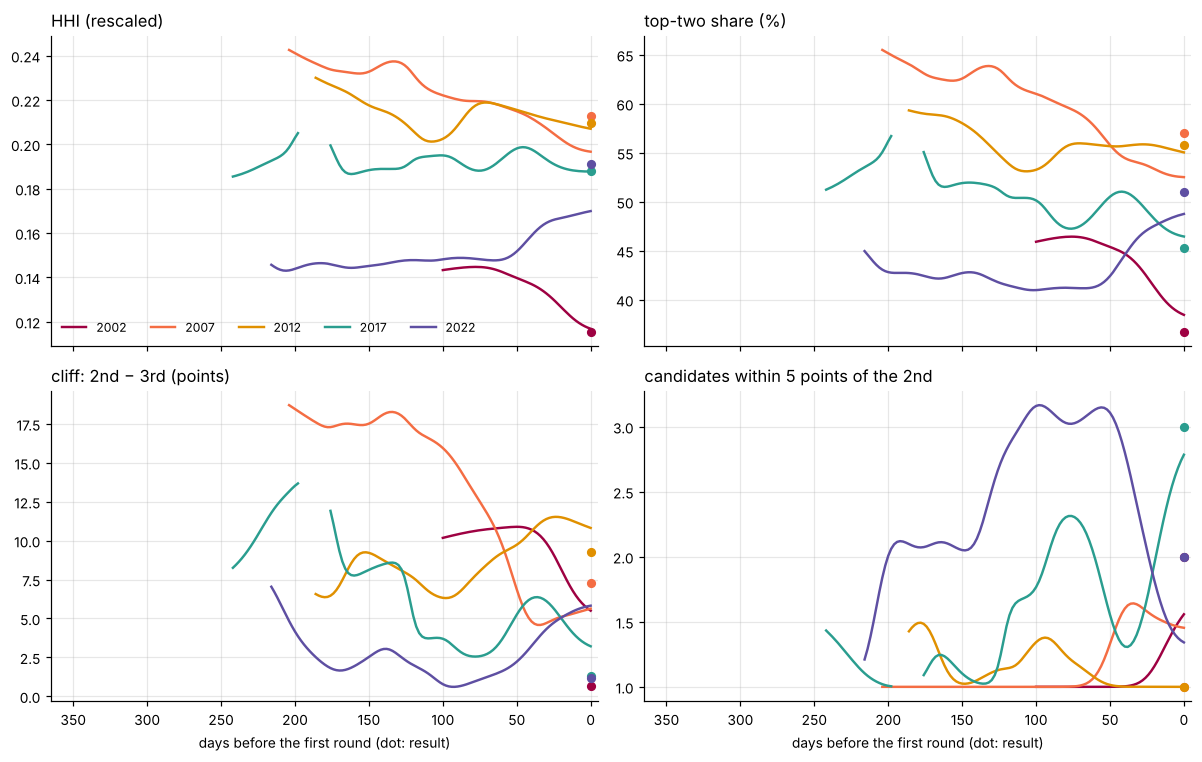

In [4]:
GRID = np.arange(0, 366, 2)
show = {"hhi": "HHI (rescaled)", "top2_share": "top-two share (%)", "cliff": "cliff: 2nd − 3rd (points)",
        "n_in_contention": "candidates within 5 points of the 2nd"}
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
evol = []
for ax, (m, label) in zip(axes.flat, show.items()):
    for e in ELECTIONS:
        d = per_poll[per_poll["election"] == e]
        s = average.smooth(d["days_before"].to_numpy(), d[m].to_numpy(dtype=float), GRID)
        evol.append(s.assign(metric=m, election=e).reset_index())
        ax.plot(s.index, s["mean"], color=E_COLOURS[e], lw=1.6, label=str(e))
        ax.plot(0, per_result.loc[e, m], "o", color=E_COLOURS[e], ms=5)
    ax.set_title(label, loc="left")
axes[0, 0].legend(frameon=False, ncol=5, fontsize=8)
for ax in axes[1]:
    ax.set_xlim(365, -5); ax.set_xlabel("days before the first round (dot: result)")
fig.tight_layout()
fig.savefig(FIGURES / "structure_over_campaign.png")
pd.concat(evol).query("days_before % 14 == 0").round(4).to_csv(TABLES / "structure_poll_average.csv", index=False)